## Load the Mall Customer dataset and re-examine its structure (shape, dtypes, missing values, summary statistics).

In [15]:
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
pd.read_csv('Mall_Customers.csv')

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40
...,...,...,...,...,...
195,196,Female,35,120,79
196,197,Female,45,126,28
197,198,Male,32,126,74
198,199,Male,32,137,18


In [3]:
df = pd.read_csv('Mall_Customers.csv')

In [4]:
df.head()

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


In [9]:
print(df.shape)
print(df.dtypes)
print(df.isnull().sum())

(200, 5)
CustomerID                 int64
Gender                    object
Age                        int64
Annual Income (k$)         int64
Spending Score (1-100)     int64
dtype: object
CustomerID                0
Gender                    0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64


In [10]:
df.describe

<bound method NDFrame.describe of      CustomerID  Gender  Age  Annual Income (k$)  Spending Score (1-100)
0             1    Male   19                  15                      39
1             2    Male   21                  15                      81
2             3  Female   20                  16                       6
3             4  Female   23                  16                      77
4             5  Female   31                  17                      40
..          ...     ...  ...                 ...                     ...
195         196  Female   35                 120                      79
196         197  Female   45                 126                      28
197         198    Male   32                 126                      74
198         199    Male   32                 137                      18
199         200    Male   30                 137                      83

[200 rows x 5 columns]>

In [11]:
df.columns

Index(['CustomerID', 'Gender', 'Age', 'Annual Income (k$)',
       'Spending Score (1-100)'],
      dtype='object')

### Select relevant numerical features (Annual Income, Spending Score, Age) and scale them using StandardScaler.

In [13]:
from sklearn.preprocessing import StandardScaler
features = df[['Annual Income (k$)', 'Spending Score (1-100)', 'Age']]

# Scale the features
scaler = StandardScaler()
scaled_features = scaler.fit_transform(features)

scaled_df = pd.DataFrame(scaled_features, columns=features.columns)
scaled_df.head()

,Annual Income (k$),Spending Score (1-100),Age
0,-1.738999,-0.434801,-1.424569
1,-1.738999,1.195704,-1.281035
2,-1.700830,-1.715913,-1.352802
3,-1.700830,1.040418,-1.137502
4,-1.662660,-0.395980,-0.563369


### Fit K-Means for a range of k values (1–10) and plot the Elbow Method curve to determine the optimal k.

In [16]:
from sklearn.cluster import KMeans

# compute WCSS
wcss = []
for k in range(1,11):
    kmeans = KMeans(n_clusters=k, init='k-means++', random_state=42, n_init=10)
    kmeans.fit(scaled_features)
    wcss.append(kmeans.inertia_)


C:\ProgramData\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1429: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\ProgramData\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1429: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\ProgramData\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1429: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\ProgramData\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1429: UserWarning: KMeans is known to have a memory leak on Window

### Plot the elbow curve


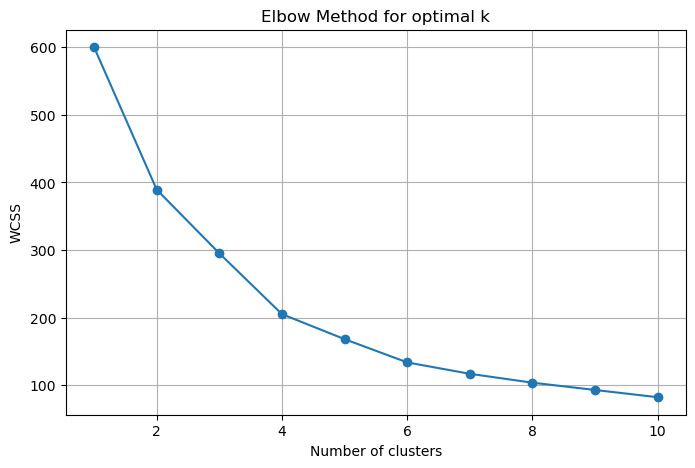

In [17]:
plt.figure(figsize=(8, 5))
plt.plot(range(1,11), wcss, marker='o')
plt.title('Elbow Method for optimal k')
plt.xlabel('Number of clusters')
plt.ylabel('WCSS')
plt.grid('True')
plt.show()

### Fit the final K-Means model with the chosen k, visualize the resulting clusters with a 2D scatter plot, and compute the Silhouette Score.

C:\ProgramData\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1429: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


Silhouette Score for k=5: 0.4166


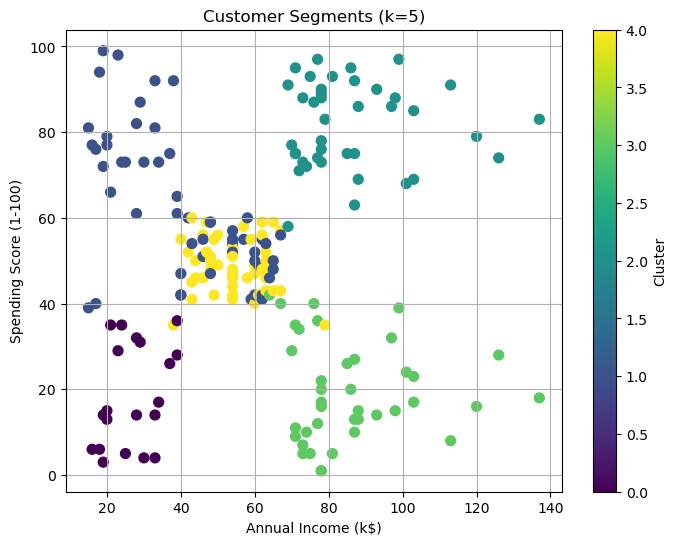

In [18]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import matplotlib.pyplot as plt

# Fit final K-Means model with chosen k (example: k=5)
k = 5
kmeans = KMeans(n_clusters=k, init='k-means++', random_state=42, n_init=10)
cluster_labels = kmeans.fit_predict(scaled_features)

# Add cluster labels back to the original dataframe
df['Cluster'] = cluster_labels

# Compute Silhouette Score
sil_score = silhouette_score(scaled_features, cluster_labels)
print(f"Silhouette Score for k={k}: {sil_score:.4f}")

# 2D scatter plot (using Annual Income vs Spending Score)
plt.figure(figsize=(8, 6))
scatter = plt.scatter(
    df['Annual Income (k$)'],
    df['Spending Score (1-100)'],
    c=cluster_labels,
    cmap='viridis',
    s=50
)
plt.title(f'Customer Segments (k={k})')
plt.xlabel('Annual Income (k$)')
plt.ylabel('Spending Score (1-100)')
plt.colorbar(scatter, label='Cluster')
plt.grid(True)
plt.show()

### Plot a dendrogram using Ward linkage and fit Agglomerative (Hierarchical) Clustering with the number of clusters read off the dendrogram.

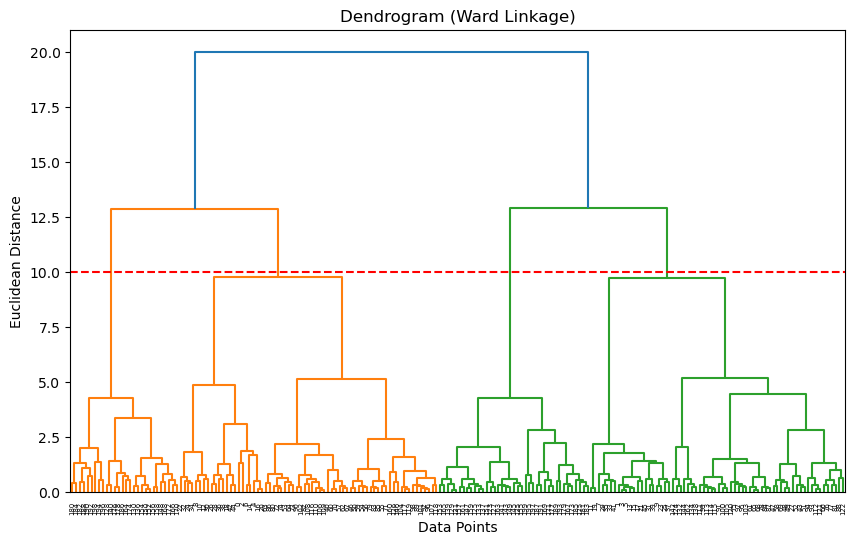

In [19]:
from scipy.cluster.hierarchy import dendrogram, linkage
from sklearn.cluster import AgglomerativeClustering
import matplotlib.pyplot as plt

# Compute the linkage matrix using Ward's method
linked = linkage(scaled_features, method='ward')

# Plot the dendrogram
plt.figure(figsize=(10, 6))
dendrogram(linked)
plt.title('Dendrogram (Ward Linkage)')
plt.xlabel('Data Points')
plt.ylabel('Euclidean Distance')
plt.axhline(y=10, color='r', linestyle='--')  # adjust this line to mark your cutoff
plt.show()

### Fit DBSCAN, tuning eps and min_samples using a k-distance plot, and visualize the resulting clusters including noise points (label = -1).

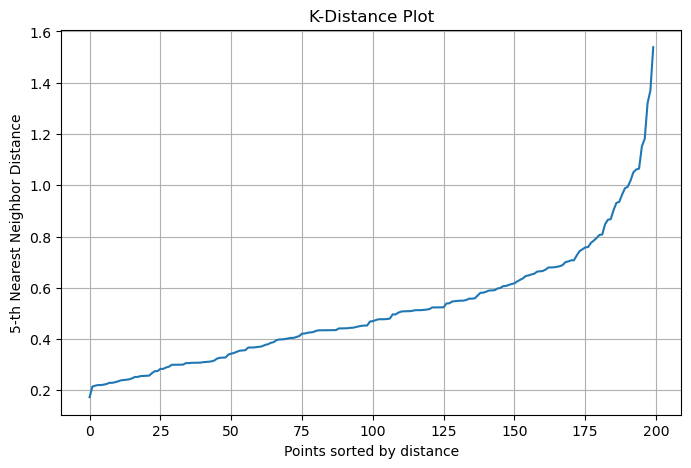

In [21]:
from sklearn.neighbors import NearestNeighbors
from sklearn.cluster import DBSCAN
import numpy as np
import matplotlib.pyplot as plt

# Step 1: Use a k-distance plot to help choose eps
# Rule of thumb: min_samples = 2 * number of dimensions (here we have 3 features, so try 5-6)
min_samples = 5

neighbors = NearestNeighbors(n_neighbors=min_samples)
neighbors_fit = neighbors.fit(scaled_features)
distances, indices = neighbors_fit.kneighbors(scaled_features)

# Sort distances to the k-th nearest neighbor
k_distances = np.sort(distances[:, min_samples - 1])

plt.figure(figsize=(8, 5))
plt.plot(k_distances)
plt.title('K-Distance Plot')
plt.xlabel('Points sorted by distance')
plt.ylabel(f'{min_samples}-th Nearest Neighbor Distance')
plt.grid(True)
plt.show()

Number of clusters: 6
Number of noise points: 60


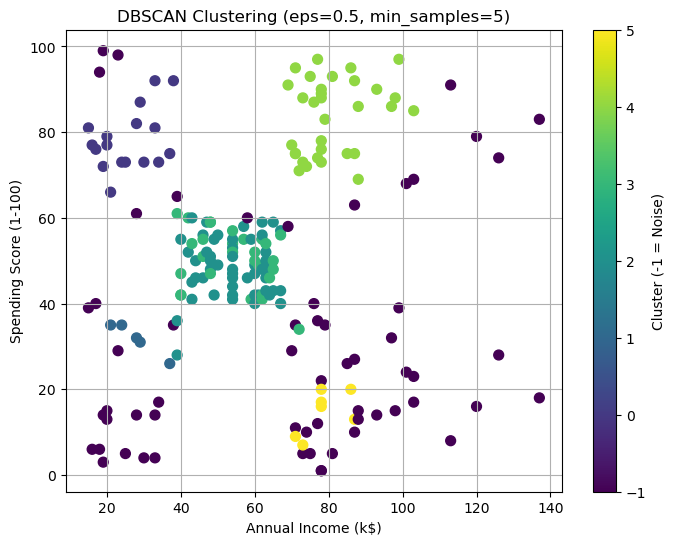

In [22]:
# Step 2: Fit DBSCAN with chosen eps (example: 0.5 — adjust based on your k-distance plot)
eps = 0.5
dbscan = DBSCAN(eps=eps, min_samples=min_samples)
dbscan_labels = dbscan.fit_predict(scaled_features)

df['DBSCAN_Cluster'] = dbscan_labels

# Check how many clusters and how many noise points were found
n_clusters = len(set(dbscan_labels)) - (1 if -1 in dbscan_labels else 0)
n_noise = list(dbscan_labels).count(-1)
print(f"Number of clusters: {n_clusters}")
print(f"Number of noise points: {n_noise}")

# Step 3: Visualize the clusters, including noise points
plt.figure(figsize=(8, 6))
scatter = plt.scatter(
    df['Annual Income (k$)'],
    df['Spending Score (1-100)'],
    c=dbscan_labels,
    cmap='viridis',
    s=50
)
plt.title(f'DBSCAN Clustering (eps={eps}, min_samples={min_samples})')
plt.xlabel('Annual Income (k$)')
plt.ylabel('Spending Score (1-100)')
plt.colorbar(scatter, label='Cluster (-1 = Noise)')
plt.grid(True)
plt.show()